In [2]:
import pandas as pd 
import sklearn
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 
from IPython.display import Image 
%matplotlib inline

In [3]:
URL = "https://github.com/ageron/handson-ml2/blob/master/datasets/housing/housing.csv?raw=true"
df = pd.read_csv(URL)
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
from sklearn.model_selection import train_test_split    
train_set, test_set = train_test_split(df, test_size=0.2, random_state=30)

X = train_set.drop('median_house_value', axis=1)
y = train_set['median_house_value'].copy()
X_num = X.drop('ocean_proximity', axis=1)

In [5]:
from sklearn.base import BaseEstimator, TransformerMixin

rooms_ix, bedrooms_ix, population_ix, households_ix = 3, 4, 5, 6# bu datadan shu indexlardagilarni ajratib olyapmiz

class CombinedAttributesAdder(BaseEstimator, TransformerMixin):
    def __init__(self, add_bedrooms_per_room = True):
        self.add_bedrooms_per_room = add_bedrooms_per_room
    def fit(self,X, y=None):
        return self
    def transform(self, X):
        rooms_per_household = X[:, rooms_ix] / X[:, households_ix]# honalarni oilaga bulyapmiz shunda har bir oilaga nechta honaligi malum buladi
        population_per_household = X[:, population_ix] / X[:, households_ix]
        if self.add_bedrooms_per_room:# add_bedrooms_per_room ustuni ixtiyoriy buladi
            bedrooms_per_room = X[:, bedrooms_ix] / X[:, rooms_ix]
            return np.c_[X, rooms_per_household, population_per_household, bedrooms_per_room]
        else:
            return np.c_[X, rooms_per_household, population_per_household]


In [6]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler #yoki min_max_scalerdan ham foydalansa buladi

num_pipeline = Pipeline([
    ('median_qiymatlar', SimpleImputer(strategy='median')),# 1-qadam
    ('AttributesAdder', CombinedAttributesAdder(add_bedrooms_per_room = True)),
    ('standar_scaler_bir_deopazonga_tushurish', StandardScaler())
])

In [7]:
from sklearn.compose import ColumnTransformer

num_atributs = list(X_num)
str_atributs = ['ocean_proximity']

full_pipeline = ColumnTransformer([
    ('num', num_pipeline, num_atributs),# 1-nomi 2-pipelineni choqiramiz 3-qaysi ustunlar ustida pipeline ishlaganini aytypapmiz
    ('categorical', OneHotEncoder(), str_atributs)
])

## bu qiymatlar endi Ml uchun ishlatiladi

In [8]:
X_prepared = full_pipeline.fit_transform(X)
X_prepared

array([[ 0.69045468, -0.74771271,  0.82109487, ...,  0.        ,
         0.        ,  0.        ],
       [ 0.73042911, -0.79459048,  0.50456328, ...,  0.        ,
         0.        ,  0.        ],
       [ 0.80538117, -0.76646382, -0.36589859, ...,  0.        ,
         0.        ,  0.        ],
       ...,
       [ 1.11018621, -1.20242712, -0.91982888, ...,  0.        ,
         0.        ,  1.        ],
       [ 0.68046107, -0.74302493,  1.21675935, ...,  0.        ,
         0.        ,  0.        ],
       [ 0.88033323, -0.69145938, -1.15722757, ...,  0.        ,
         0.        ,  0.        ]])

# linear regression

In [9]:
from sklearn.linear_model import LinearRegression 

LR_model = LinearRegression()

In [10]:
LR_model.fit(X_prepared, y)

LinearRegression()

## endi ml ozi shu 3qator kod bilan yaratiladi lekin datani tayyorlash asosiy ish bizda!!

In [11]:
test_data = X.sample(10)
test_data

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
9364,-122.54,37.94,39.0,3670.0,775.0,1519.0,788.0,4.4081,NEAR BAY
3955,-118.62,34.20,32.0,3233.0,553.0,1678.0,545.0,5.0025,<1H OCEAN
3294,-122.65,38.99,16.0,4279.0,951.0,1596.0,666.0,1.8571,INLAND
15389,-117.12,33.27,11.0,3016.0,601.0,1727.0,541.0,4.9375,<1H OCEAN
18854,-122.45,41.28,15.0,2740.0,503.0,1188.0,445.0,3.4519,INLAND
4082,-118.38,34.16,42.0,2358.0,546.0,1065.0,523.0,3.1289,<1H OCEAN
9456,-123.71,39.88,42.0,1518.0,383.0,656.0,303.0,1.4952,NEAR OCEAN
3423,-118.42,34.27,33.0,937.0,216.0,1216.0,212.0,3.3214,<1H OCEAN
17446,-120.48,34.65,26.0,1933.0,316.0,1001.0,319.0,4.4628,NEAR OCEAN
6648,-118.14,34.17,52.0,2687.0,600.0,1716.0,544.0,2.7201,<1H OCEAN


In [12]:
test_label = y.loc[test_data.index]
test_label

9364     435200.0
3955     234900.0
3294      75900.0
15389    232800.0
18854    128800.0
4082     320600.0
9456      69800.0
3423     131300.0
17446    134400.0
6648     205700.0
Name: median_house_value, dtype: float64

In [13]:
test_data_prepared = full_pipeline.transform(test_data)
predic = LR_model.predict(test_data_prepared)
predic

array([301807.76233565, 266527.08627782, 106593.79824032, 227085.41417112,
        80289.72791212, 228711.18728711, 153924.47031112, 173906.90748088,
       278138.63936492, 190497.23217587])

In [14]:
predic_data = pd.DataFrame({'asil data': test_label, 'predict': predic})

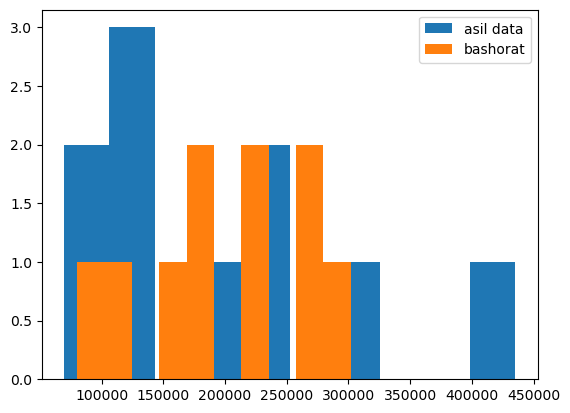

In [15]:
plt.hist(predic_data['asil data'], label='asil data')
plt.hist(predic_data['predict'], label='bashorat')
plt.legend()
plt.show()


<Axes: >

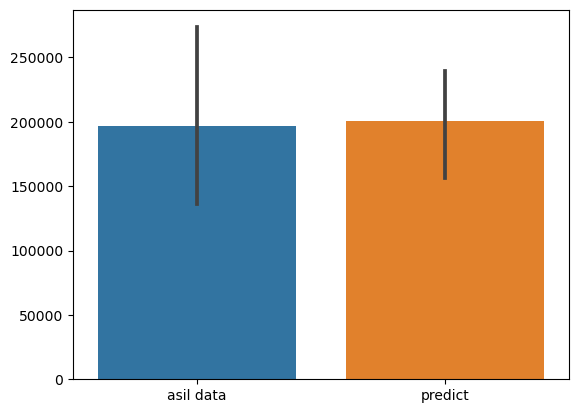

In [16]:
sns.barplot(predic_data)

<Axes: >

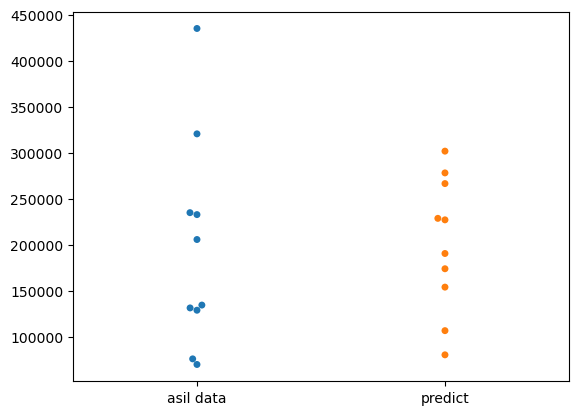

In [17]:
sns.swarmplot(predic_data)

# modelni baxolash

In [18]:
test_set

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
19449,-121.03,37.68,20.0,3204.0,625.0,2016.0,605.0,2.6567,110400.0,INLAND
10452,-117.66,33.46,26.0,2073.0,370.0,952.0,340.0,5.0877,288100.0,<1H OCEAN
18982,-122.01,38.26,12.0,4132.0,710.0,2087.0,633.0,4.5987,139700.0,INLAND
8187,-118.11,33.78,16.0,3985.0,567.0,1327.0,564.0,7.9767,500001.0,<1H OCEAN
15759,-122.44,37.77,52.0,2994.0,736.0,1428.0,700.0,3.0766,438900.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
12704,-121.41,38.58,18.0,6955.0,1882.0,2803.0,1740.0,3.0890,141400.0,INLAND
18742,-122.34,40.57,26.0,2187.0,472.0,1339.0,463.0,2.0395,67900.0,INLAND
19142,-122.69,38.32,15.0,2536.0,414.0,1400.0,426.0,5.6613,172400.0,<1H OCEAN
1027,-120.55,38.46,16.0,1443.0,249.0,435.0,181.0,3.2031,129200.0,INLAND


In [19]:
X_test = test_set.drop('median_house_value', axis=1)
y_test = test_set['median_house_value'].copy()

In [20]:
X_test_prepered = full_pipeline.transform(X_test)

In [21]:
y_predict = LR_model.predict(X_test_prepered)

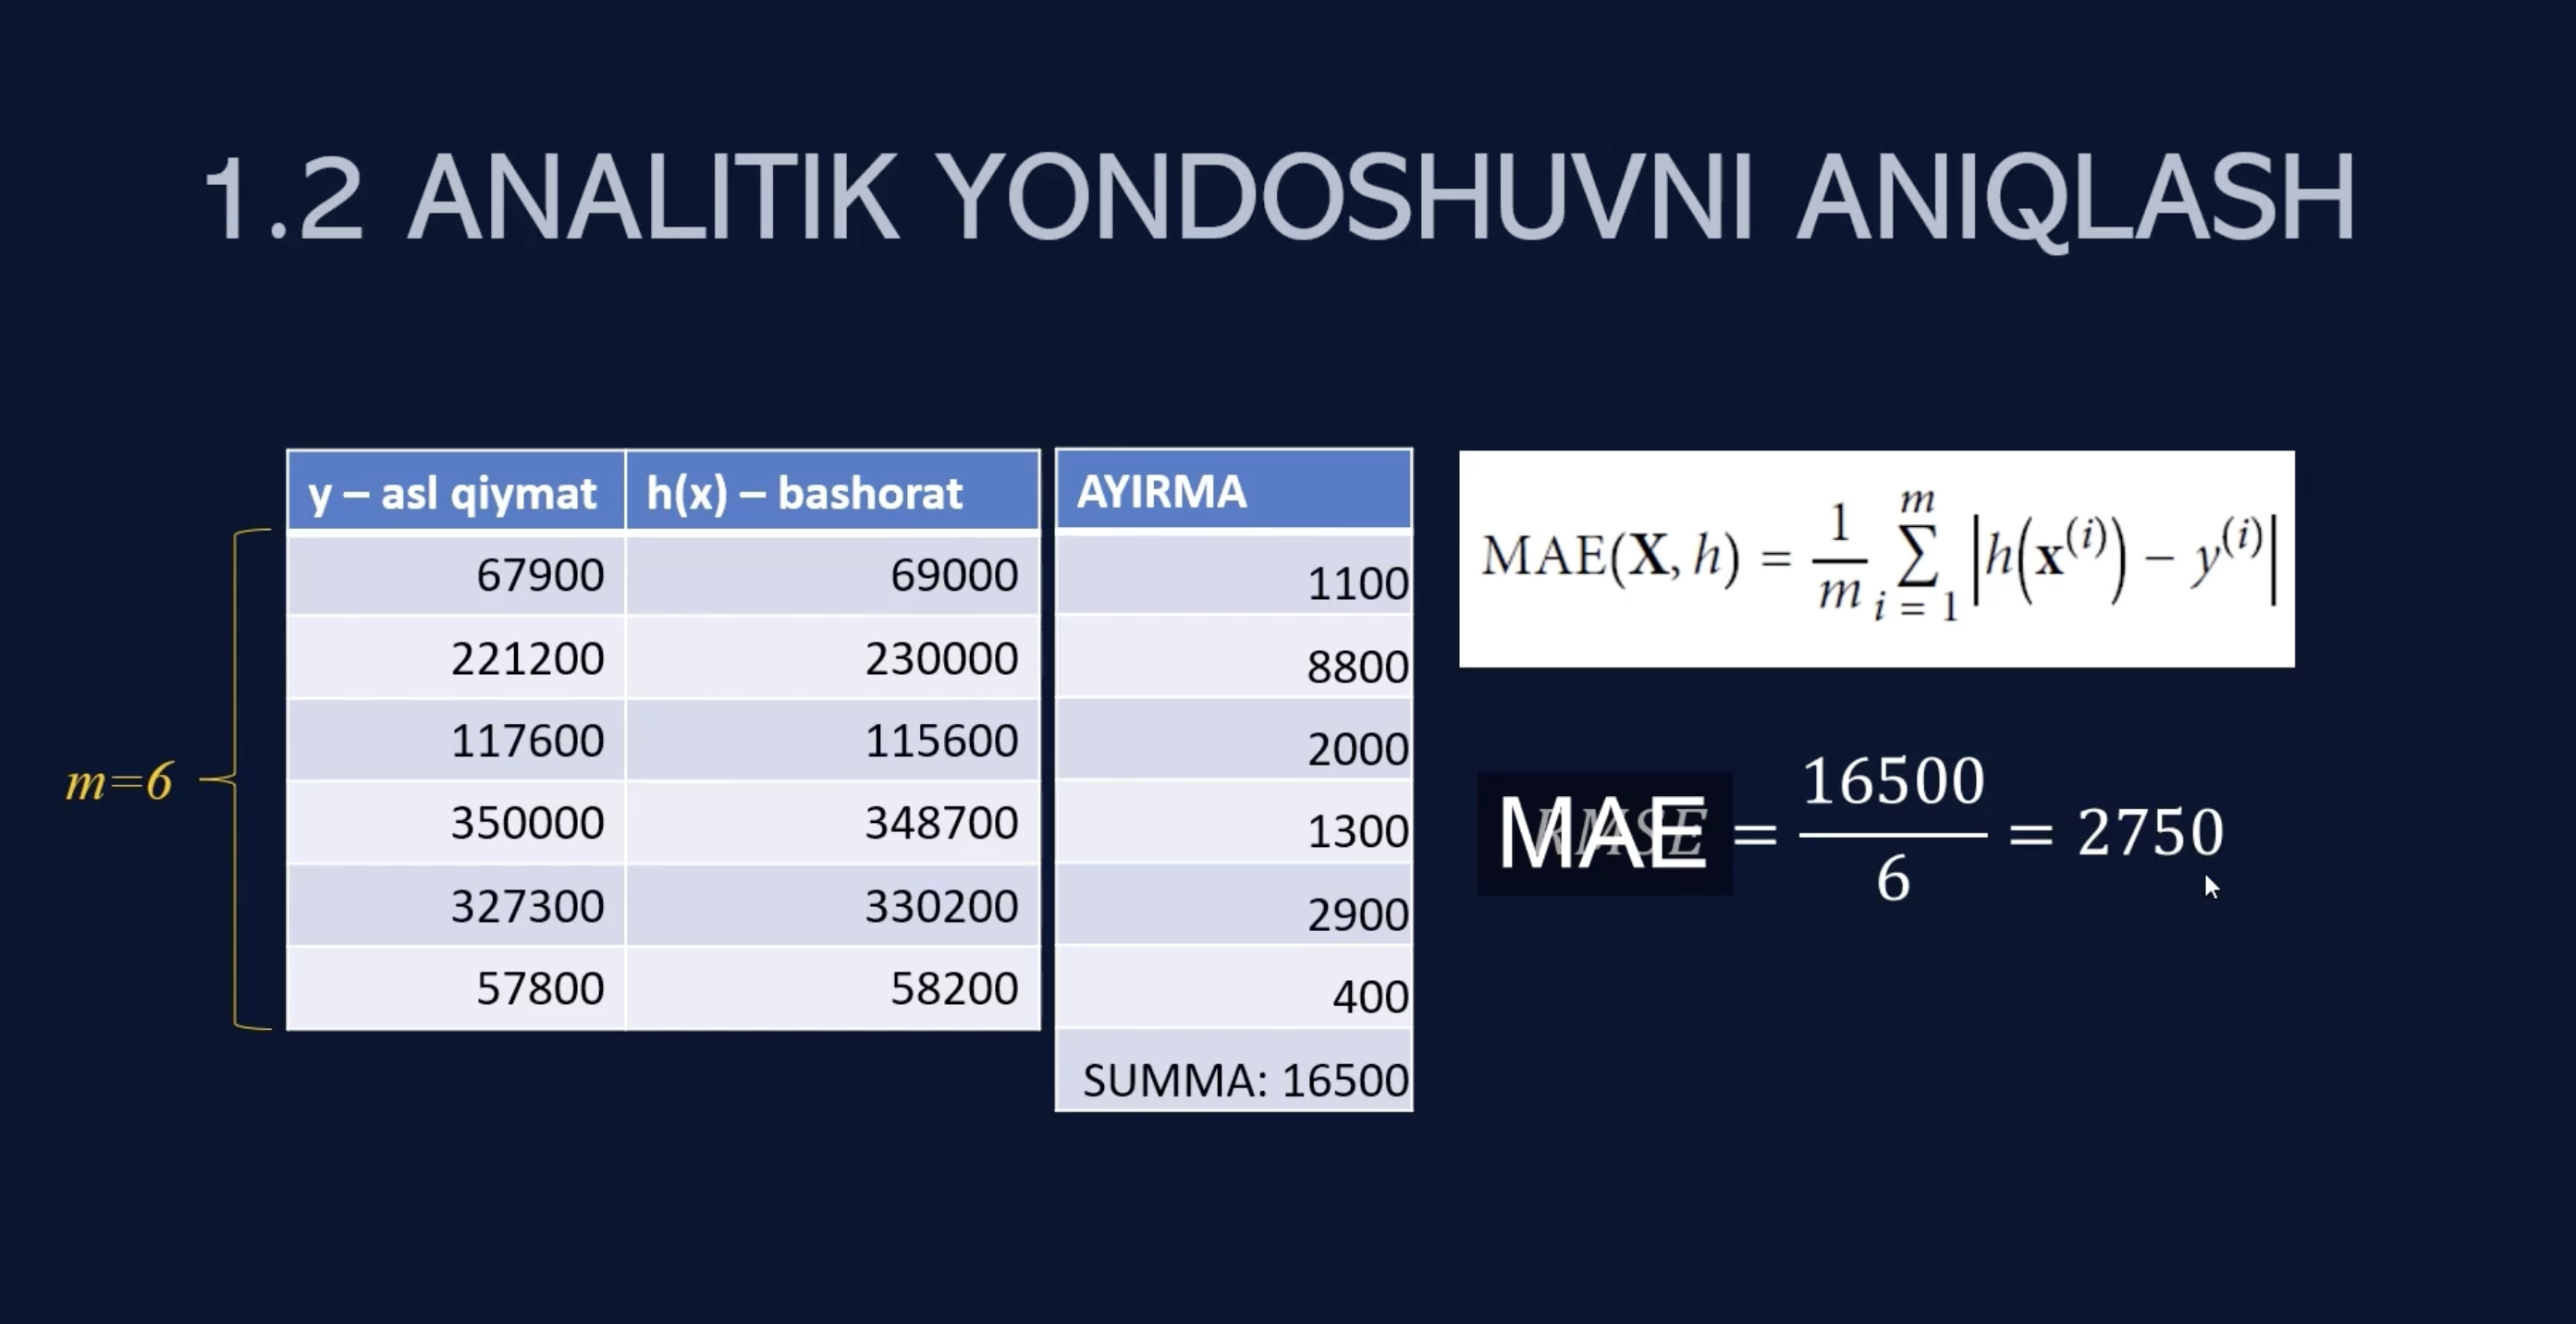

In [22]:
Image('MAE.png', width=500)

In [23]:
from sklearn.metrics import mean_absolute_error

mea = mean_absolute_error(y_test, y_predict)
print(f"o'rtacha absolut hatolik {mea}")

o'rtacha absolut hatolik 50785.898108736044


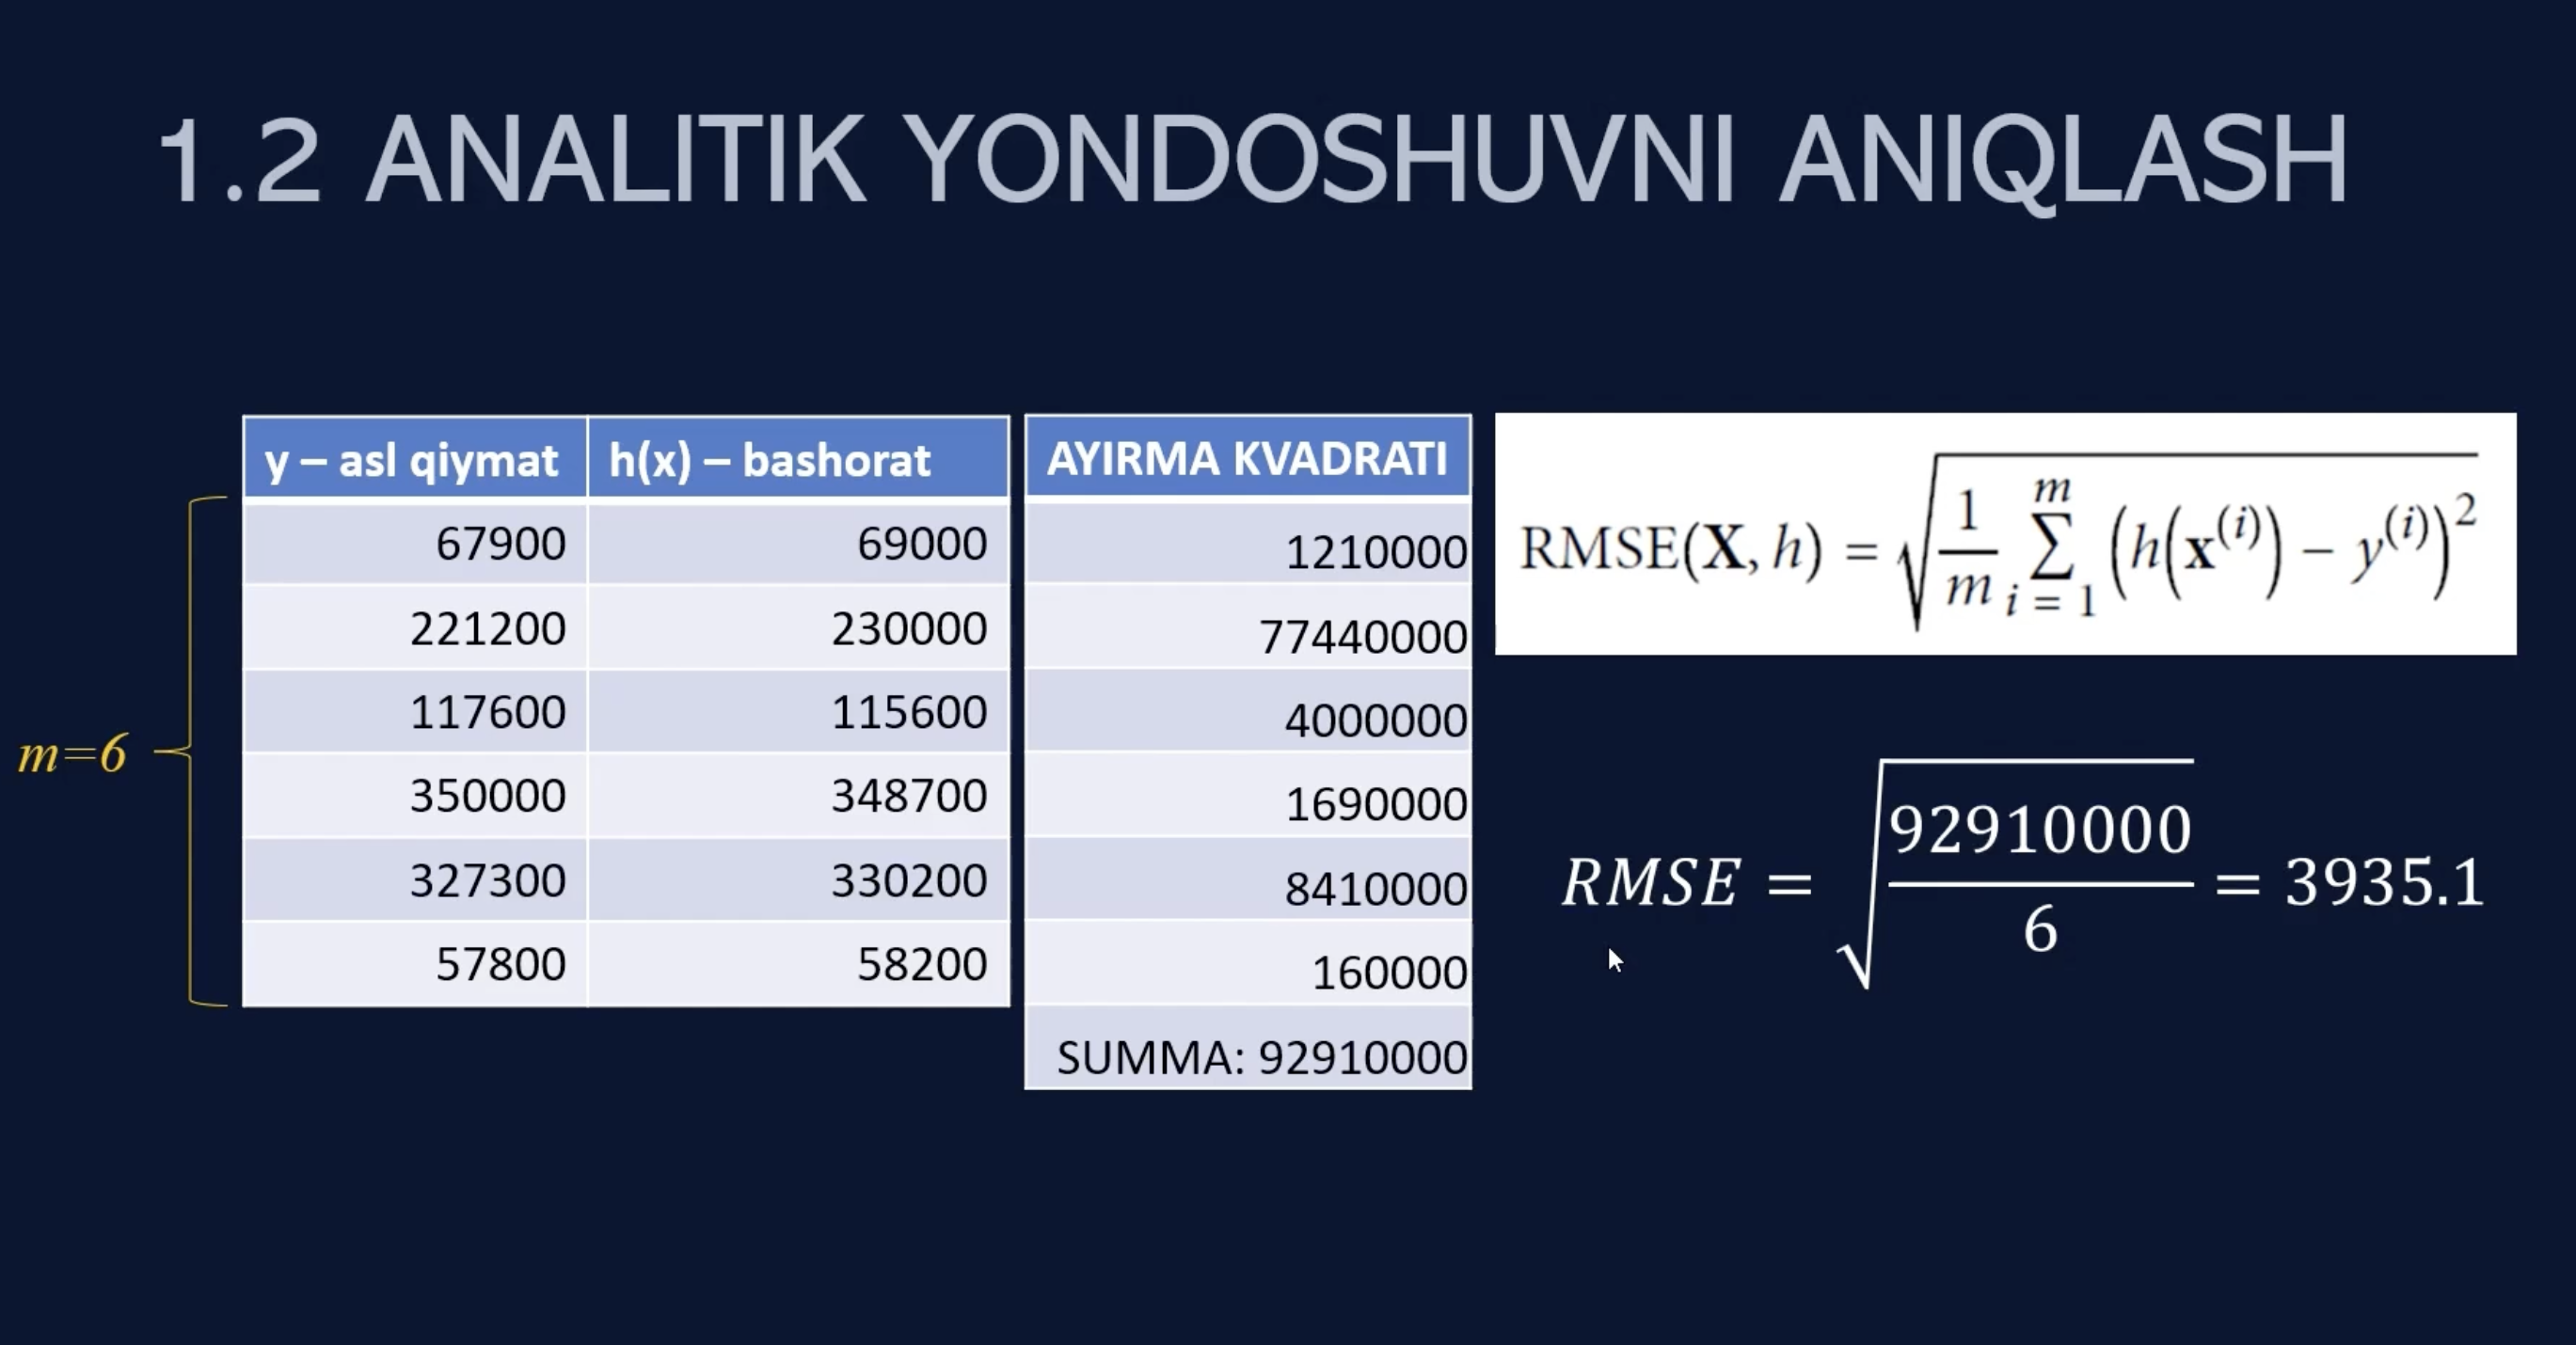

In [24]:
Image('RMSE.png', width=500)

In [25]:
from sklearn.metrics import mean_squared_error 

mse = mean_squared_error(y_test, y_predict)
print(f"o'rtacha kvadrat hatolik {np.sqrt(mse)}")# bunda oxirida ildizdan chiqarishimiz kerak

o'rtacha kvadrat hatolik 71845.87679177962


## biz ML dan qoniqmadik demak boshqa algoritimlarni korib chiqishimiz kerak

# RandomForestRegression

In [26]:
from sklearn.ensemble import RandomForestRegressor 

RF_model = RandomForestRegressor()
RF_model.fit(X_prepared, y)

RandomForestRegressor()

In [27]:
y_predict = RF_model.predict(X_test_prepered)

In [28]:
from sklearn.metrics import mean_squared_error 

mse = mean_squared_error(y_test, y_predict)
print(f"o'rtacha kvadrat hatolik {np.sqrt(mse)}")

o'rtacha kvadrat hatolik 51517.142146297854


In [40]:
y_predict

array([ 98942.  , 261514.02, 157165.  , ..., 242339.  , 150458.  ,
       287677.  ])

In [44]:
RF_model.score(X_test_prepered,y_test)

0.8075610991624217

# Cross-Validation

## Cross-Validation usuli bilan baholash

Yuqorida biz modelni baholash uchun ma'lumotlarni test va train setlarga ajratdik. 
Bu usulning kamchiligi biz test va train uchun doim bir xil ma'lumotlardan foydalanayapmiz. 

Cross-validation yordamida biz ma'lumotlarni bir necha qismga ajratib, modelni turli qismlar yordamida bir nechta bor train va test qilishimiz mumkin. 

Misol uchun, quyidagi rasmda ma'lumotlarni 5 ga ajratib train va test qilish ko'rsatilgan.

![](https://www.oreilly.com/library/view/machine-learning-quick/9781788830577/assets/b90b29ab-dfe7-4c11-9a2f-321e84f79495.png)

## cross-validation bizga modelni baxolashda yordam beradi misol 5 desak datani beshga bolib har bir qismda test data buladi keyin bu model 5 marta qayta qayta test data bilan sinab koradi.

In [49]:
X = train_set.drop('median_house_value', axis=1)
y = train_set['median_house_value'].copy()

X_prepared = full_pipeline.transform(X)

In [50]:
from sklearn.model_selection import cross_val_score 

crs = cross_val_score(LR_model, X_prepared, y, scoring="neg_mean_squared_error", cv=5)

In [53]:
def display_score(scores):
    print('scores', scores)
    print('mean', np.mean(scores))
    print('std', np.std(scores))# standart ogish
display_score(np.sqrt(-crs))
    

scores [68967.51775739 69013.20545295 67955.06231316 67033.63542174
 66134.56734578]
mean 67820.79765820419
std 1115.1526698623584


## ortacha hatolik 67ming

In [54]:
crs_rd = cross_val_score(RF_model, X_prepared, y, scoring="neg_mean_squared_error", cv=10)
rsscore = np.sqrt(-crs_rd)
display_score(rsscore)

scores [50560.04829662 51072.10148638 49783.39015261 46050.32645085
 49021.1720851  53485.28398388 49784.85337882 48949.70488644
 48897.03239679 50012.1835876 ]
mean 49761.60967050703
std 1789.217694231013


# bunda hatolik esa 49ming

# Modelni saqlash

In [55]:
import pickle

filename = 'RFmodel.pkl'
with open(filename, 'wb') as file:
    pickle.dump(RF_model, file)

In [ ]:
# with open(filename, 'rb') as file:
#     model = pickle.load(file)

# joblib

In [56]:
import joblib 

filename = 'RF_model.jbl'
joblib.dump(RF_model, filename)

['RF_model.jbl']